### This notebook includes the basic joint GCS and PCS using Gumbel-softmax differentiable sampling technique. Initialization with a known constellation is required when bit metric decoding is used. In this notebook we add PAS constraint, upsampling, filtering and PAPR.

In [1]:
%reset

In [31]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Layer, Dense, LayerNormalization
from tensorflow.nn import relu
from tensorflow.keras.losses import CategoricalCrossentropy, BinaryCrossentropy
from sionna.phy.block import Block
from sionna.phy.utils import expand_to_rank, hard_decisions
from sionna.phy.mapping import Constellation
import sionna as sn
import matplotlib.pyplot as plt
import os
import gc

In [32]:
devices = tf.config.list_physical_devices('GPU')
print(len(devices))

1


In [33]:
symbol_points_qam32 =   np.array([-0.6708 + 1.1180j,
-0.2236 + 1.1180j,
-0.2236 + 0.6708j,
-0.2236 + 0.2236j,
-1.1180 + 0.6708j,
-1.1180 + 0.2236j,
-0.6708 + 0.6708j,
-0.6708 + 0.2236j,
-0.6708 - 1.1180j,
-0.2236 - 1.1180j,
-0.2236 - 0.6708j,
-0.2236 - 0.2236j,
-1.1180 - 0.6708j,
-1.1180 - 0.2236j,
-0.6708 - 0.6708j,
-0.6708 - 0.2236j,
 0.6708 + 1.1180j,
 0.2236 + 1.1180j,
 0.2236 + 0.6708j,
 0.2236 + 0.2236j,
 1.1180 + 0.6708j,
 1.1180 + 0.2236j,
 0.6708 + 0.6708j,
 0.6708 + 0.2236j,
 0.6708 - 1.1180j,
 0.2236 - 1.1180j,
 0.2236 - 0.6708j,
 0.2236 - 0.2236j,
 1.1180 - 0.6708j,
 1.1180 - 0.2236j,
 0.6708 - 0.6708j,
 0.6708 - 0.2236j])

In [34]:
def normalize_constellation(points, probabilities):

    # Compute the power of the constellation
    power = np.sum(probabilities * np.abs(points)**2)
    # Normalize the constellation points
    normalized_points = points / np.sqrt(power)
    return normalized_points

def plot_constellation_wlabels(points, probabilities, plot_title):

    points = np.asarray(points)
    probabilities = np.asarray(probabilities).flatten()

    # Scale marker sizes for visibility
    marker_sizes = 300 * probabilities / max(probabilities)

    plt.figure(figsize=(8, 8))
    plt.scatter(points.real, points.imag, s=marker_sizes, alpha=0.7, c='b', edgecolors='k')

    # Annotate with 6-bit binary labels
    for i, pt in enumerate(points):
        label = format(i, '05b')  # 6-bit binary string
        plt.text(pt.real + 0.05, pt.imag + 0.05, label, fontsize=9, ha='left', va='bottom', color='darkred')

    # Add grid and formatting
    plt.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.axvline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.grid(True, linestyle=':')
    plt.xlabel("In-phase")
    plt.ylabel("Quadrature")
    plt.title(plot_title)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.tight_layout()
    # plt.show()

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

def plot_constellation_wlabels2(points, probabilities, plot_title):

    points = np.asarray(points)
    probabilities = np.asarray(probabilities).flatten()

    # Avoid zero issues
    eps = 1e-12
    p = np.clip(probabilities, eps, None)

    # --- Log-based size scaling ---
    gamma = 2.5
    p_norm = (p - p.min()) / (p.max() - p.min())
    size_scaled = p_norm ** gamma

    marker_sizes = 100 + 2000 * size_scaled


    plt.figure(figsize=(8, 8))

    sc = plt.scatter(
        points.real,
        points.imag,
        s=marker_sizes,
        c=p,
        cmap='plasma',
        norm=plt.Normalize(vmin=p.min(), vmax=p.max()),
        edgecolors='k',
        alpha=0.9
    )

    # Annotate with 6-bit binary labels
    for i, pt in enumerate(points):
        label = format(i, '06b')
        plt.text(
            pt.real + 0.05,
            pt.imag + 0.05,
            label,
            fontsize=8,
            ha='left',
            va='bottom',
            color='black'
        )

    # Formatting
    plt.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.axvline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.grid(True, linestyle=':', alpha=0.3)
    plt.xlabel("In-phase")
    plt.ylabel("Quadrature")
    plt.title(plot_title)
    plt.gca().set_aspect('equal', adjustable='box')

    # Colorbar (log scale)
    cbar = plt.colorbar(sc)
    cbar.set_label("Probability (log scale)")

    plt.tight_layout()



In [35]:
class Modulator(Layer):

    def __init__(self, constellation, N,  parity_k, **kwargs):
        super(Modulator, self).__init__(**kwargs)

        # Define the real and imaginary parts of the constellation as trainable variables
        # self.constellation_real = tf.Variable(constellation.real, dtype=tf.float32, trainable=True)
        # self.constellation_imag = tf.Variable(constellation.imag, dtype=tf.float32, trainable=True)
        self.constellation_real_init = constellation.real
        self.constellation_imag_init = constellation.imag
        self.parity_k = parity_k
        self.N = N

    def build(self, input_shape):
        self.constellation_real = self.add_weight(
            name="constellation_real",
            shape=self.constellation_real_init.shape,
            initializer=tf.constant_initializer(self.constellation_real_init),
            trainable=True
        )
        self.constellation_imag = self.add_weight(
            name="constellation_imag",
            shape=self.constellation_imag_init.shape,
            initializer=tf.constant_initializer(self.constellation_imag_init),
            trainable=True
        )

    def call(self, s, probabilities):
        # Combine the real and imaginary parts into a complex-valued constellation
        constellation_combined = tf.complex(self.constellation_real, self.constellation_imag)

        # Expand the signal dimension to align for matrix multiplication
        s = tf.expand_dims(s, axis=-1)

        # Normalize the constellation
        normalization_constants = tf.sqrt(
            tf.reduce_sum(tf.reshape((2**parity_k)*probabilities * tf.abs(constellation_combined) ** 2,(1,(2**self.parity_k),int(self.N/(2**self.parity_k)))), 2)
        )
        normalization_constants = tf.expand_dims(normalization_constants, axis=2)
        normalization_constants = tf.complex(tf.reshape(tf.tile(normalization_constants,(1,1,int(self.N/(2**self.parity_k)))),(1,self.N)),0.0)
        norm_constellation = constellation_combined / normalization_constants

        # print('norm_constellation',norm_constellation.shape)
        # print('s',s.shape)
        # Compute the modulated signal
        x_real = tf.matmul(tf.math.real(norm_constellation), s)
        x_imag = tf.matmul(tf.math.imag(norm_constellation), s)
        x = tf.complex(x_real, x_imag)

        return tf.squeeze(x, axis=[-1, -2]), norm_constellation

class SymbolLogits2LLRs_Prob_Aware(Block):

    def __init__(self,
                 method,
                 num_bits_per_symbol,
                 *,
                 hard_out=False,
                 precision=None,
                 **kwargs):
        super().__init__(precision=precision, **kwargs)
        assert method in ("app","maxlog"), "Unknown demapping method"
        self._method = method
        self._hard_out = hard_out
        self._num_bits_per_symbol = num_bits_per_symbol
        num_points = int(2**num_bits_per_symbol)
        a = np.zeros([num_points, num_bits_per_symbol])
        for i in range(0, num_points):
            a[i,:] = np.array(list(np.binary_repr(i, num_bits_per_symbol)),
                              dtype=np.int32)
        c0 = np.zeros([int(num_points/2), num_bits_per_symbol])
        c1 = np.zeros([int(num_points/2), num_bits_per_symbol])
        for i in range(num_bits_per_symbol-1,-1,-1):
            c0[:,i] = np.where(a[:,i]==0)[0]
            c1[:,i] = np.where(a[:,i]==1)[0]
        self._c0 = tf.constant(c0, dtype=tf.int32) # Symbols with ith bit=0
        self._c1 = tf.constant(c1, dtype=tf.int32) # Symbols with ith bit=1
        a = 2*a-1
        self._a = tf.constant(a, dtype=self.rdtype)
        if self._method == "app":
            self._reduce = tf.reduce_logsumexp
        else:
            self._reduce = tf.reduce_max

    @property
    def num_bits_per_symbol(self):
        """
        `int` : Number of bits per symbol
        """
        return self._num_bits_per_symbol

    def call(self, logits, probabilities):
        # Compute exponents
        exponents = logits
        exp0 = tf.gather(exponents, self._c0, axis=-1, batch_dims=0)
        exp1 = tf.gather(exponents, self._c1, axis=-1, batch_dims=0)
        exp_ps = expand_to_rank(tf.math.log(probabilities), tf.rank(logits), axis=0)
        exp_ps0 = tf.gather(exp_ps, self._c0, axis=-1)
        exp_ps1 = tf.gather(exp_ps, self._c1, axis=-1)
        llr = self._reduce(exp_ps1 + exp1, axis=-2)\
                - self._reduce(exp_ps0 + exp0, axis=-2)
        if self._hard_out:
            return hard_decisions(llr)
        else:
            return llr

class Demapper_Prob_Aware(Block):
    # pylint: disable=line-too-long

    def __init__(self,
                 demapping_method,
                 num_bits_per_symbol=None,
                 hard_out=False,
                 precision=None,
                 **kwargs):
        super().__init__(precision=precision, **kwargs)

        self._logits2llrs = SymbolLogits2LLRs_Prob_Aware(demapping_method,
                                              num_bits_per_symbol,
                                              hard_out=hard_out,
                                              precision=precision,
                                              **kwargs)

        self._no_threshold = tf.cast(np.finfo(self.rdtype.as_numpy_dtype).tiny,
                                     self.rdtype)

    def call(self, y, no, points, probabilities):

        squared_dist = tf.pow(tf.abs(tf.expand_dims(y, axis=-1) - points), 2)
        no = tf.expand_dims(no, axis=-1)
        no = tf.math.maximum(no, self._no_threshold)
        exponents = -squared_dist/no
        llr = self._logits2llrs(exponents, probabilities)

        return llr

In [36]:
class Demodulator_bitwise(Layer):
    def __init__(self, bits_per_symbol):
        super(Demodulator_bitwise, self).__init__()
        self.dense1 = Dense(128, activation='relu')  # First Dense Layer
        self.dense2 = Dense(128, activation='relu')  # Second Dense Layer
        self.dense3 = Dense(bits_per_symbol, activation='sigmoid')                      # Output Dense Layer
        # self.snr_db = snr_db                        # SNR in dB

    def call(self, y, batch_size, block_size):
        # Ensure complex-valued input is split into real and imaginary parts
        y_real = tf.math.real(y)
        y_imag = tf.math.imag(y)

        # Create and broadcast SNR tensor
        snr_tensor = tf.constant([[1]], dtype=tf.float32)
        brd_snr_tensor = tf.broadcast_to(snr_tensor, [batch_size, block_size, 1])

        # Concatenate real, imaginary, and SNR tensors along the last dimension
        y_real = tf.expand_dims(y_real,axis=-1)
        y_imag = tf.expand_dims(y_imag,axis=-1)
        # print('y_real',y_real.shape)
        # print('y_imag',y_imag.shape)
        # print('brd_snr_tensor',brd_snr_tensor.shape)
        stack_input = tf.concat([y_real, y_imag, brd_snr_tensor], axis=2)

        ## print('brd_snr_tensor.shape: ',brd_snr_tensor)

        # Pass the stacked input through the dense layers
        x = self.dense1(stack_input)
        x = self.dense2(x)
        logits = self.dense3(x)

        return logits

In [37]:
class SamplingMechanism(Layer):
    def __init__(self, N, tau, parity_k):
        super(SamplingMechanism, self).__init__()
        self.dense1 = Dense(128, activation='relu')
        self.dense2 = Dense(int(N/(2**parity_k)), activation=None)
        self.tau = tau
        # self.snr_db = snr_db
        self.parity_k = parity_k
        self.N = N

    def call(self, batch_size, block_size):
        # Create a tensor with the SNR value
        snr_tensor = tf.constant([[1]], dtype=tf.float32)
        # Pass the SNR value through the first dense layer
        a = self.dense1(snr_tensor)

        # Pass through the second dense layer
        logits = self.dense2(a)
        # print('1',logits.shape)
        #
        # Copying the logits 2**parity_k times to constrain according to PAS
        logits = tf.tile(logits, [1, 2**self.parity_k])
        # print('2',logits.shape)

        # Compute softmax output
        softmax_out = tf.nn.softmax(logits, axis=-1)

        logits = tf.expand_dims(logits, axis=1)
        # print('3',logits.shape)
        logits = tf.tile(logits, [batch_size, block_size, 1])

        # Compute Gumbel-Softmax with straight-through sampling
        gumbel_dist = -tf.math.log(-tf.math.log(tf.random.uniform(tf.shape(logits), 0, 1) + 1e-20) + 1e-20)
        gumbel_logits = logits + gumbel_dist
        gumbel_softmax = tf.nn.softmax(gumbel_logits / self.tau, axis=-1)

        max_value = tf.argmax(gumbel_softmax, axis=-1)
        # print(gumbel_softmax.shape)

        # Step 2: Compare each value in gumbel_softmax with the max_value
        hard_sample = tf.one_hot(max_value, depth=self.N, dtype=tf.float32)
        # print("hard_sample:", hard_sample)

        straight_through = gumbel_softmax + tf.stop_gradient(hard_sample - gumbel_softmax)

        return straight_through, softmax_out



In [38]:
class EndToEndSystem_bitwise(Model):
    def __init__(self, N, constellation, papr_batch_size, batch_size, block_size, bits_per_symbol, parity_k, use_upsampling_filtering, tau=1.0):
        super(EndToEndSystem_bitwise, self).__init__()
        # self.No = 1/(10**(snr_db/10))
        self.sampling = SamplingMechanism(N, tau, parity_k)
        self.batch_size = batch_size
        self.papr_batch_size = papr_batch_size
        self.block_size = block_size
        self.modulator = Modulator(constellation,N,parity_k)
        self.channel = sn.phy.channel.AWGN()
        # Neural demapper
        # self.demodulator = Demodulator_bitwise(bits_per_symbol)
        # MAP prob aware demapper
        self.demodulator = Demapper_Prob_Aware("app",bits_per_symbol)
        self.loss_fn = BinaryCrossentropy(from_logits=False, reduction='none', axis=[0, 1])
        self.bits_per_symbol = bits_per_symbol
        self.parity_k = parity_k
        self.use_upsampling_filtering = use_upsampling_filtering
        self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
        self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                      offset = self.rx_filter.length - 1,

                                                 num_symbols=tf.cast(block_size, tf.int32))
    def call(self, No):
        # Sampling mechanism generates symbol indices and shaping probabilities

        s, shaping_probs = self.sampling(batch_size = self.batch_size, block_size = self.block_size)
        indices = tf.argmax(s, axis=2, output_type=tf.int64)  # use int64 here!
        # Step 2: Convert to binary bits
        shifts = tf.range(self.bits_per_symbol - 1, -1, -1, dtype=tf.int64)  # also int64
        # Right shift and mask
        bit_repr = tf.bitwise.right_shift(
            tf.expand_dims(indices, -1), shifts
        ) & 1

        # Modulate the symbols
        x_mod, norm_const = self.modulator(s, shaping_probs)

        if self.use_upsampling_filtering:
            x_up = self.upsampler(x_mod)
            x_tx_filt = self.tx_filter(x_up)
            y_channel = self.channel(x_tx_filt, No)
            y_rx_filt = self.rx_filter(y_channel)
            y = self.downsampler(y_rx_filt)
        else:
            # Transmit through the channel
            y = self.channel(x_mod, No)

        # Demodulate the received signal
        # logits = self.demodulator(y, batch_size = self.batch_size, block_size = self.block_size)
        logits = self.demodulator(y,No,norm_const,shaping_probs)

        loss_ordinary = tf.reduce_sum(self.loss_fn(bit_repr,logits))
        entropy_value = -tf.reduce_sum(shaping_probs * tf.math.log(shaping_probs))
        loss = loss_ordinary - entropy_value

        return loss, loss_ordinary, entropy_value, shaping_probs

    @tf.function
    def compute_power_to_average_power_samples(self):
        s_power, shaping_probs_power = self.sampling( batch_size = self.papr_batch_size, block_size = self.block_size)
        x_power,_ = self.modulator(s_power, shaping_probs_power)
        x_up_power = self.upsampler(x_power)
        x_tx_filt_power = self.tx_filter(x_up_power)  # 'same' for discarding the edges
        p_x = tf.square(tf.abs(x_tx_filt_power))
        power_samples = p_x / tf.reduce_mean(p_x)
        # entropy_value_power = -tf.reduce_sum(shaping_probs_power * tf.math.log(shaping_probs_power))
        return power_samples

In [60]:
## Inner loop
@tf.function
def _inner_loop(lambd_papr, mu, step, num_it, excess_power_target, papr_threshold, No):
    # We need to initialize c...
    excess_power = 0.0
    c_excess_power = excess_power
    L = 0.0

    k = tf.constant(0, tf.int32)
    while tf.less(k, num_it):
        with (tf.GradientTape() as tape):
            loss,loss_ordinary, entropy_value,_ = model(No)

            if use_upsampling_filtering:
                powers = model.compute_power_to_average_power_samples()
                excess_power = tf.reduce_mean(tf.nn.relu(powers[:,64:-64]  - papr_threshold))
                excess_power = tf.math.log(excess_power + 1e-12) / tf.math.log(10.)
                c_excess_power = excess_power - excess_power_target
                c_excess_power = tf.maximum(c_excess_power,lambd_papr / mu)

                # excess_H = tf.maximum(entropy_target - entropy_value,lambd_H / mu)

            # Augmented Lagrangian
            L = loss - lambd_papr * c_excess_power + 0.5 * mu * (tf.square(c_excess_power))
            #+ (1/(2*mu))*(tf.square(tf.nn.relu(lambd_H + mu*(entropy_target - entropy_value))) - lambd_H**2)
            # - lambd_H * excess_H + 0.5 * mu * (tf.square(excess_H))


        # Computing and applying gradients
        weights = model.trainable_weights
        grads = tape.gradient(L, weights)
        grads, glob_norm = tf.clip_by_global_norm(grads, 0.1)
        optimizer.apply_gradients(zip(grads, weights))
        # Print progress
        if k % 50 == 0:
          tf.print('Iteration',k,'L', L / np.log(2),'loss', loss / np.log(2), 'loss_ordinary', loss_ordinary / np.log(2), 'entropy_value', entropy_value / np.log(2),'glob_norm',glob_norm)

        k = k + 1
        step = step + 1

    if use_upsampling_filtering:
        powers = model.compute_power_to_average_power_samples()
        excess_power = tf.reduce_mean(tf.nn.relu(powers[:,64:-64] - papr_threshold))
        excess_power = tf.math.log(excess_power + 1e-12) / tf.math.log(10.)
        c_excess_power = excess_power - excess_power_target
        c_excess_power = tf.maximum(c_excess_power,lambd_papr / mu)
        # entropy_power= -tf.reduce_sum(probs * tf.math.log(probs))

    return c_excess_power, step



### One-time training

In [40]:
###############################
# Train function
###############################
N = 32  # Number of classes (symbols)
bits_per_symbol = int(np.log2(N))

parity_k = 2
use_upsampling_filtering = True  # Remove 'false' this after testing without upsampling and filtering

constellation = symbol_points_qam32

snr_db = 15 # SNR in dB

tau = 10

# Batch size
batch_size = 10
papr_batch_size = 40
block_size = 4096

model = EndToEndSystem_bitwise(N, constellation, papr_batch_size, batch_size, block_size, bits_per_symbol, parity_k, use_upsampling_filtering, tau)

In [41]:
No = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)
_,_,_,_ = model(No)

In [61]:
###############################
# Train function
###############################
N = 32  # Number of classes (symbols)
bits_per_symbol = int(np.log2(N))

parity_k = 2
use_upsampling_filtering = True  # Remove 'false' this after testing without upsampling and filtering

constellation = symbol_points_qam32

snr_db = 15 # SNR in dB

tau = 10

# Batch size
batch_size = 10
papr_batch_size = 40
block_size = 4096

model = EndToEndSystem_bitwise(N, constellation, papr_batch_size, batch_size, block_size, bits_per_symbol, parity_k, use_upsampling_filtering, tau)

# No = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)
# _,_,_,_ = model(No)

ebno_db = tf.random.uniform(shape=[batch_size], minval=5.0, maxval=13.0)
No = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=bits_per_symbol, coderate=1)
No = tf.expand_dims(No, axis=-1)

excess_power_target = -5.0 #B
# entropy_target = 5.5*0.693
papr_threshold_db = 6.0 #dB
papr_threshold = tf.math.pow(10.0, papr_threshold_db / 10.0)
# We define a new optimizer at every rune
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# Outer-loop
# Lagrange multiplier
lambd_papr = tf.Variable(tf.constant(0.0, tf.float32), trainable=False, dtype=tf.float32)
# lambd_H = tf.Variable(tf.constant(0.0, tf.float32), trainable=False, dtype=tf.float32)

# Penalty parameter
mu = tf.Variable(0.01, trainable=False, dtype=tf.float32)

step = tf.constant(0, tf.int32)
for i in range(50):

    # Find a local minimizer (increase the first number of iterations if using random initializations)
    if i == 0:
        num_it = 500
    else:
        num_it = 35
    c_excess_power, step = _inner_loop(lambd_papr, mu, step, num_it,
                                       excess_power_target, papr_threshold, No)

    # Update Lagrange multipliers
    tf.print('-------------------------------------------------------')
    tf.print('-------------------------------------------------------')
    tf.print('Progress ',i,' % ','c_excess_power',c_excess_power,'lambd_papr',lambd_papr,'mu',mu)
    tf.print('-------------------------------------------------------')
    tf.print('-------------------------------------------------------')

    lambd_papr = lambd_papr - mu * c_excess_power
    # lambd_H = tf.nn.relu(lambd_H + mu * (entropy_target - entropy_value))
    # excess_H = tf.maximum(entropy_target - entropy_value,lambd_H / mu)
    # lambd_H = lambd_H - mu*excess_H

    # Update penalty parameter
    mu = mu*1.003

Iteration 0 L -2.48593426 loss -2.48593426 loss_ordinary 2.50563884 entropy_value 4.99157333 glob_norm 4.31150103
Iteration 50 L -3.54035735 loss -3.55761719 loss_ordinary 1.25137198 entropy_value 4.80898905 glob_norm 0.831729472
Iteration 100 L -3.66641903 loss -3.69784427 loss_ordinary 0.962553859 entropy_value 4.66039801 glob_norm 0.829464078
Iteration 150 L -3.69247961 loss -3.72193265 loss_ordinary 0.940327168 entropy_value 4.66225958 glob_norm 5.85094357
Iteration 200 L -3.71679473 loss -3.74427485 loss_ordinary 0.92349267 entropy_value 4.66776752 glob_norm 0.647665322
Iteration 250 L -3.69251943 loss -3.71884274 loss_ordinary 0.947722077 entropy_value 4.66656494 glob_norm 0.58796972
Iteration 300 L -3.7075336 loss -3.73762465 loss_ordinary 0.891658485 entropy_value 4.62928295 glob_norm 0.758166254
Iteration 350 L -3.68858933 loss -3.71110082 loss_ordinary 0.989494324 entropy_value 4.7005949 glob_norm 1.09365761
Iteration 400 L -3.76362634 loss -3.79285169 loss_ordinary 0.8423367

[[0.00972898 0.01999764 0.03727641 0.08448563 0.01036086 0.01655719
  0.02325384 0.04833943 0.00972898 0.01999764 0.03727641 0.08448563
  0.01036086 0.01655719 0.02325384 0.04833943 0.00972898 0.01999764
  0.03727641 0.08448563 0.01036086 0.01655719 0.02325384 0.04833943
  0.00972898 0.01999764 0.03727641 0.08448563 0.01036086 0.01655719
  0.02325384 0.04833943]]
snr_15_PAPR_6.0_target_-5.0


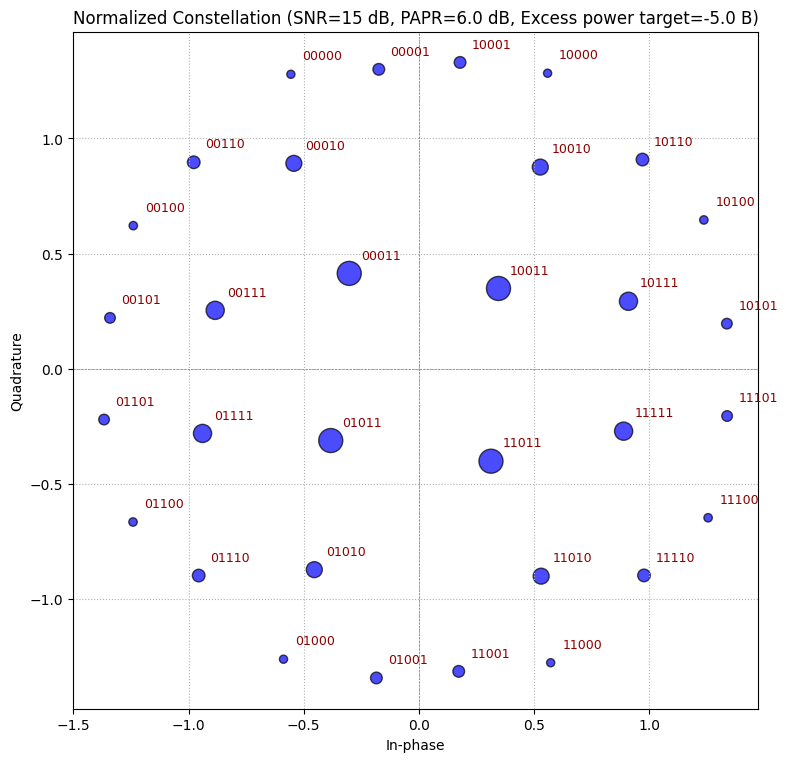

In [62]:
with tf.GradientTape(persistent=False) as tape:
#     tape.watch(model.trainable_variables)  # Ensure variables are watched if needed, but no gradients will be calculated
    _,_,_,shaping_probs = model(No)


# Define constellation points (complex numbers)
points = model.modulator.constellation_real.numpy()+ 1j*model.modulator.constellation_imag.numpy()

# Define probabilities for each point
probabilities = shaping_probs.numpy()
# probs_log = probabi
# plt.savefig('const.pdf')

# Normalize the constellation
normalized_points = normalize_constellation(points, probabilities)

title_plot = f"Normalized Constellation (SNR={snr_db} dB, PAPR={papr_threshold_db} dB, Excess power target={excess_power_target} B)"
# Plot the constellation
plot_constellation_wlabels(normalized_points, probabilities, title_plot)
file_name = f"snr_{snr_db}_PAPR_{papr_threshold_db}_target_{excess_power_target}"
print(probabilities)
print(file_name)


[[2.0970583e-08 7.5288045e-07 1.0742902e-02 2.8143462e-04 5.4576697e-07
  1.3589005e-02 2.7944082e-02 2.8476227e-02 1.2703267e-02 2.7787186e-02
  2.4051132e-02 2.4956124e-02 2.0732351e-04 2.8640905e-02 2.4746463e-02
  2.5872633e-02 2.0970583e-08 7.5288045e-07 1.0742902e-02 2.8143462e-04
  5.4576697e-07 1.3589005e-02 2.7944082e-02 2.8476227e-02 1.2703267e-02
  2.7787186e-02 2.4051132e-02 2.4956124e-02 2.0732351e-04 2.8640905e-02
  2.4746463e-02 2.5872633e-02 2.0970583e-08 7.5288045e-07 1.0742902e-02
  2.8143462e-04 5.4576697e-07 1.3589005e-02 2.7944082e-02 2.8476227e-02
  1.2703267e-02 2.7787186e-02 2.4051132e-02 2.4956124e-02 2.0732351e-04
  2.8640905e-02 2.4746463e-02 2.5872633e-02 2.0970583e-08 7.5288045e-07
  1.0742902e-02 2.8143462e-04 5.4576697e-07 1.3589005e-02 2.7944082e-02
  2.8476227e-02 1.2703267e-02 2.7787186e-02 2.4051132e-02 2.4956124e-02
  2.0732351e-04 2.8640905e-02 2.4746463e-02 2.5872633e-02]]
snr_25_PAPR_6.0_target_-10


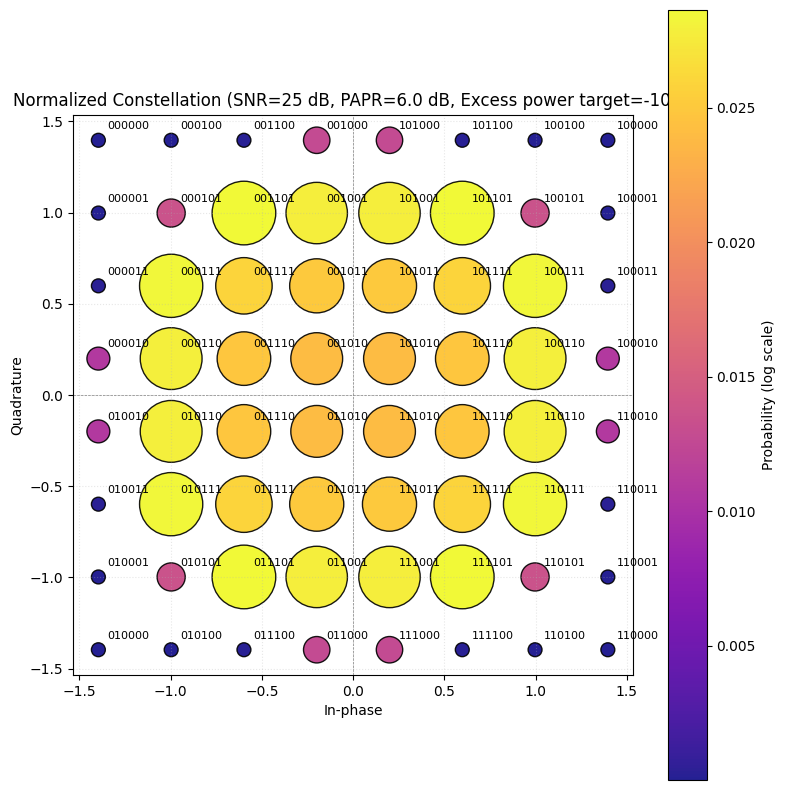

In [91]:
with tf.GradientTape(persistent=False) as tape:
#     tape.watch(model.trainable_variables)  # Ensure variables are watched if needed, but no gradients will be calculated
    _,_,_,shaping_probs = model(No)


# Define constellation points (complex numbers)
points = model.modulator.constellation_real.numpy()+ 1j*model.modulator.constellation_imag.numpy()

# Define probabilities for each point
probabilities = shaping_probs.numpy()
# probs_log = probabi
# plt.savefig('const.pdf')

# Normalize the constellation
normalized_points = normalize_constellation(points, probabilities)

title_plot = f"Normalized Constellation (SNR={snr_db} dB, PAPR={papr_threshold_db} dB, Excess power target={excess_power_target} B)"
# Plot the constellation
plot_constellation_wlabels2(normalized_points, probabilities, title_plot)
file_name = f"snr_{snr_db}_PAPR_{papr_threshold_db}_target_{excess_power_target}"
print(probabilities)
print(file_name)


### Training for several SNR and PAPR values

In [13]:
RESULTS_DIR = "results_prob_aware"

snr_list = [13]
papr_list = [6.0, 7.0, 8.0]

In [105]:
# @tf.function
def run_experiment(snr_db, papr_threshold_db):
    print(f"\n===== Running SNR={snr_db} dB | PAPR={papr_threshold_db} dB =====\n")

    # No_ = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)
    ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=15.0)
    No_ = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=bits_per_symbol, coderate=1)
    No_ = tf.expand_dims(No_, axis=-1)

    papr_threshold_ = tf.math.pow(10.0, papr_threshold_db / 10.0)
    excess_power_target_ = -5.0 #B

    lambd_papr = tf.Variable(tf.constant(0.0, tf.float32), trainable=False, dtype=tf.float32)
    mu = tf.Variable(0.01, trainable=False, dtype=tf.float32)
    step = tf.constant(0, tf.int32)

    for i in range(10):
        if i == 0:
            num_it = 5000
        else:
            num_it = 500
        c_excess_power, step = _inner_loop(lambd_papr, mu, step,
                                           num_it, excess_power_target_,
                                           papr_threshold_, No_)

        # Update Lagrange multipliers
        tf.print('-------------------------------------------------------')
        tf.print('-------------------------------------------------------')
        tf.print('Progress ',i,' % ','c_excess_power',c_excess_power,'lambd_papr',lambd_papr,'mu',mu)
        tf.print('-------------------------------------------------------')
        tf.print('-------------------------------------------------------')
        lambd_papr = lambd_papr - mu * c_excess_power

        # Update penalty parameter
        mu = mu*1.003

    # ------------------
    # Save constellation
    # ------------------
    with tf.GradientTape() as tape:
        _, _, _, shaping_probs = model(No_)

    points = (
        model.modulator.constellation_real.numpy()
        + 1j * model.modulator.constellation_imag.numpy()
    )
    probs = shaping_probs.numpy()

    normalized_points = normalize_constellation(points, probs)

    exp_name = f"snr_{snr_db}_papr_{papr_threshold_db}"
    # np.save(f"{RESULTS_DIR}/{exp_name}_points.npy", normalized_points)
    # np.save(f"{RESULTS_DIR}/{exp_name}_probs.npy", probs)

    plt.figure()
    plot_constellation_wlabels(
        normalized_points,
        probs,
        f"SNR={snr_db} dB, PAPR={papr_threshold_db} dB"
    )
    plt.savefig(f"{RESULTS_DIR}/{exp_name}_constellation.png")
    plt.close()

    # ------------------
    # Compute & save CCDF
    # ------------------
    powers = tf.reshape(
        model.compute_power_to_average_power_samples(), [-1]
    )
    powers_db = 10 * tf.math.log(powers + 1e-12) / tf.math.log(10.)

    x_sorted = np.sort(powers_db.numpy())
    ccdf = 1.0 - np.arange(1, len(x_sorted) + 1) / len(x_sorted)

    np.savez(
        f"{RESULTS_DIR}/{exp_name}.npz",
        snr_db=snr_db,
        papr_db=papr_threshold_db,
        constellation_points=normalized_points,
        constellation_probabilities=probs,
        ccdf_x_db=x_sorted,
        ccdf_y=ccdf
    )


    # np.save(f"{RESULTS_DIR}/{exp_name}_ccdf_x.npy", x_sorted)
    # np.save(f"{RESULTS_DIR}/{exp_name}_ccdf_y.npy", ccdf)


    print(f"Finished {exp_name}")


In [106]:
snr_list = [13]
papr_list = [6.0, 7.0, 8.0]

N = 64  # Number of classes (symbols)
bits_per_symbol = int(np.log2(N))
parity_k = 2
use_upsampling_filtering = True  # Remove 'false' this after testing without upsampling and filtering
constellation = symbol_points_qam64

tau = 10
# snr_db = 15
# No = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)

# Batch size
batch_size = 10
papr_batch_size = 40
block_size = 4096

ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=15.0)
No = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=bits_per_symbol, coderate=1)
No = tf.expand_dims(No, axis=-1)

model = EndToEndSystem_bitwise(N, constellation, papr_batch_size,
                                batch_size, block_size,
                               bits_per_symbol, parity_k,
                               use_upsampling_filtering, tau)
_,_,_,_ = model(No)
initial_weights = model.get_weights()

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

RESULTS_DIR = "results_prob_aware"
os.makedirs(RESULTS_DIR, exist_ok=True)


for snr_db in snr_list:
    for papr_db in papr_list:
        model.set_weights(initial_weights)
        optimizer = tf.keras.optimizers.Adam(0.001)
        run_experiment(snr_db, papr_db)
        tf.keras.backend.clear_session()
        gc.collect()

print("ALL EXPERIMENTS FINISHED")



===== Running SNR=13 dB | PAPR=6.0 dB =====

Iteration 0 L -3.84451532 loss -3.85105443 loss_ordinary 2.13327718 entropy_value 5.98433161 glob_norm 3.53165317
Iteration 50 L -4.46277046 loss -4.49128962 loss_ordinary 1.37681615 entropy_value 5.86810589 glob_norm 1.37674022
Iteration 100 L -4.72893858 loss -4.7740469 loss_ordinary 0.945461512 entropy_value 5.71950817 glob_norm 2.14667058
Iteration 150 L -4.74644566 loss -4.78728151 loss_ordinary 0.926130176 entropy_value 5.71341133 glob_norm 1.00285697
Iteration 200 L -4.74186039 loss -4.77816486 loss_ordinary 0.953243136 entropy_value 5.73140764 glob_norm 1.35993421
Iteration 250 L -4.69852209 loss -4.73458481 loss_ordinary 0.977720141 entropy_value 5.71230459 glob_norm 3.19180107
Iteration 300 L -4.7712512 loss -4.80868864 loss_ordinary 0.877716303 entropy_value 5.68640518 glob_norm 3.03380585
Iteration 350 L -4.75723028 loss -4.78913212 loss_ordinary 0.929931521 entropy_value 5.71906376 glob_norm 2.15966535
Iteration 400 L -4.730093

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

### Plotting saved data

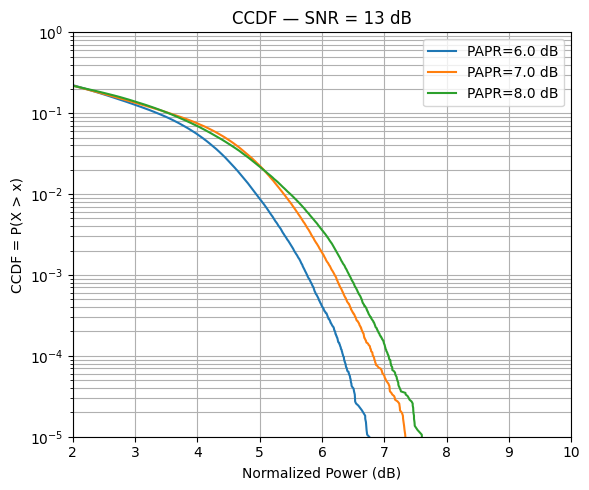

In [14]:
for snr_db in snr_list:

    plt.figure(figsize=(6, 5))

    for papr_db in papr_list:
        exp_name = f"snr_{snr_db}_papr_{papr_db}"
        data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")

        x = data["ccdf_x_db"]
        y = data["ccdf_y"]

        plt.plot(x, y, label=f"PAPR={papr_db} dB")

    plt.yscale("log")
    plt.xlabel("Normalized Power (dB)")
    plt.ylabel("CCDF = P(X > x)")
    plt.title(f"CCDF — SNR = {snr_db} dB")
    plt.grid(True, which="both")
    plt.xlim(2, 10)
    plt.ylim(1e-5, 1)
    plt.legend()

    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/ccdf_snr_{snr_db}.png", dpi=300)
    plt.show()


### Plotting a single plot

In [16]:
powers_ccdf = tf.reshape(model.compute_power_to_average_power_samples(),[-1])
powers_ccdf_db = 10*tf.math.log(powers_ccdf + 1e-12) / tf.math.log(10.)

# Sort data
x_sorted = np.sort(powers_ccdf_db.numpy())

# CCDF values
ccdf = 1.0 - np.arange(1, len(x_sorted) + 1) / len(x_sorted)

In [15]:
model.papr_batch_size = 200

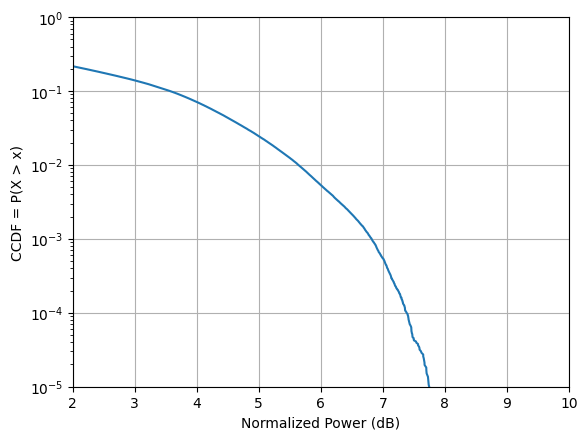

In [19]:
# Plot
plt.figure()
plt.plot(x_sorted, ccdf)
# plt.plot(x_sorted2, ccdf2)
# plt.plot(x_sorted3, ccdf3)
# plt.plot(x_sorted4, ccdf4)
plt.xlabel("Normalized Power (dB)")
plt.xlim(2, 10)
plt.ylim(1e-5, 1)
plt.ylabel("CCDF = P(X > x)")
plt.yscale("log")   # optional, very common
plt.grid(True)
plt.show()


In [20]:
np.savez(
    "QAM_prob_shaped.npz",
    ccdf_x_db=x_sorted,
    ccdf_y=ccdf
)

In [49]:
# Checking trainable parameters of the model

for v in model.trainable_weights:
    print(v.path, v.shape)

end_to_end_system_bitwise_11/sampling_mechanism_10/dense_38/kernel (1, 128)
end_to_end_system_bitwise_11/sampling_mechanism_10/dense_38/bias (128,)
end_to_end_system_bitwise_11/sampling_mechanism_10/dense_39/kernel (128, 16)
end_to_end_system_bitwise_11/sampling_mechanism_10/dense_39/bias (16,)
end_to_end_system_bitwise_11/modulator_6/constellation_real (64,)
end_to_end_system_bitwise_11/modulator_6/constellation_imag (64,)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_40/kernel (3, 128)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_40/bias (128,)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_41/kernel (128, 128)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_41/bias (128,)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_42/kernel (128, 6)
end_to_end_system_bitwise_11/demodulator_bitwise_6/dense_42/bias (6,)


### Probability aware MAP demapper

In [13]:
from sionna.phy.block import Block
from sionna.phy.utils import expand_to_rank, hard_decisions
from sionna.phy.mapping import Constellation
import tensorflow as tf
import numpy as np


In [17]:
class SymbolLogits2LLRs_Prob_Aware(Block):

    def __init__(self,
                 method,
                 num_bits_per_symbol,
                 *,
                 hard_out=False,
                 precision=None,
                 **kwargs):
        super().__init__(precision=precision, **kwargs)
        assert method in ("app","maxlog"), "Unknown demapping method"
        self._method = method
        self._hard_out = hard_out
        self._num_bits_per_symbol = num_bits_per_symbol
        num_points = int(2**num_bits_per_symbol)
        a = np.zeros([num_points, num_bits_per_symbol])
        for i in range(0, num_points):
            a[i,:] = np.array(list(np.binary_repr(i, num_bits_per_symbol)),
                              dtype=np.int32)
        c0 = np.zeros([int(num_points/2), num_bits_per_symbol])
        c1 = np.zeros([int(num_points/2), num_bits_per_symbol])
        for i in range(num_bits_per_symbol-1,-1,-1):
            c0[:,i] = np.where(a[:,i]==0)[0]
            c1[:,i] = np.where(a[:,i]==1)[0]
        self._c0 = tf.constant(c0, dtype=tf.int32) # Symbols with ith bit=0
        self._c1 = tf.constant(c1, dtype=tf.int32) # Symbols with ith bit=1
        a = 2*a-1
        self._a = tf.constant(a, dtype=self.rdtype)
        if self._method == "app":
            self._reduce = tf.reduce_logsumexp
        else:
            self._reduce = tf.reduce_max

    @property
    def num_bits_per_symbol(self):
        """
        `int` : Number of bits per symbol
        """
        return self._num_bits_per_symbol

    def call(self, logits, probabilities):
        # Compute exponents
        exponents = logits
        exp0 = tf.gather(exponents, self._c0, axis=-1, batch_dims=0)
        exp1 = tf.gather(exponents, self._c1, axis=-1, batch_dims=0)
        exp_ps = expand_to_rank(tf.math.log(probabilities), tf.rank(logits), axis=0)
        exp_ps0 = tf.gather(exp_ps, self._c0, axis=-1)
        exp_ps1 = tf.gather(exp_ps, self._c1, axis=-1)
        llr = self._reduce(exp_ps1 + exp1, axis=-2)\
                - self._reduce(exp_ps0 + exp0, axis=-2)
        if self._hard_out:
            return hard_decisions(llr)
        else:
            return llr

class Demapper_Prob_Aware(Block):
    # pylint: disable=line-too-long

    def __init__(self,
                 demapping_method,
                 num_bits_per_symbol=None,
                 hard_out=False,
                 precision=None,
                 **kwargs):
        super().__init__(precision=precision, **kwargs)

        self._logits2llrs = SymbolLogits2LLRs_Prob_Aware(demapping_method,
                                              num_bits_per_symbol,
                                              hard_out=hard_out,
                                              precision=precision,
                                              **kwargs)

        self._no_threshold = tf.cast(np.finfo(self.rdtype.as_numpy_dtype).tiny,
                                     self.rdtype)

    def call(self, y, no, points, probabilities):

        squared_dist = tf.pow(tf.abs(tf.expand_dims(y, axis=-1) - points), 2)
        no = tf.expand_dims(no, axis=-1)
        no = tf.math.maximum(no, self._no_threshold)
        exponents = -squared_dist/no
        llr = self._logits2llrs(exponents, probabilities)

        return llr

In [18]:

shape = (3, 4)

real_part = tf.random.uniform(
    shape=shape,
    minval=-1.0,
    maxval=1.0,
    dtype=tf.float32
)

imag_part = tf.random.uniform(
    shape=shape,
    minval=-1.0,
    maxval=1.0,
    dtype=tf.float32
)

y_demod = tf.complex(real_part, imag_part)

snr_db = 15
No = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)

bits_per_symbol = 6

probabilities = tf.ones([2**bits_per_symbol])/64

QAM64_const = Constellation("custom", bits_per_symbol, symbol_points_qam64)

# demodulator = Demapper_Prob_Aware("app","qam",bits_per_symbol)
demodulator = Demapper_Prob_Aware("app",bits_per_symbol)
# prior = tf.zeros([bits_per_symbol])



In [19]:
demodulator(y_demod,No,symbol_points_qam64,probabilities)

<tf.Tensor: shape=(3, 4, 6), dtype=float32, numpy=
array([[[ 28.36687   ,   6.340347  ,  -3.468565  ,   2.6575298 ,
           7.111731  ,  -0.25806618],
        [-13.374626  , -33.313633  ,   2.4293985 ,   3.7059622 ,
          -5.2804556 ,   1.0512786 ],
        [-14.125561  ,  40.258186  ,   2.0597043 ,   4.101682  ,
          -8.246021  ,  -0.9465518 ],
        [ 34.68568   ,  12.850036  ,  -5.8225317 ,   0.63289785,
           2.693655  ,   3.4307866 ]],

       [[ 34.547703  ,  -1.3680038 ,  -5.767028  ,   0.6744113 ,
          15.586769  ,  -4.875932  ],
        [ 10.700207  ,  -3.0932226 ,   3.841763  ,   2.3021755 ,
          12.076542  ,  -3.0259404 ],
        [ -8.693684  ,  -5.2031035 ,   5.086223  ,   1.2077641 ,
           8.527136  ,  -1.1127362 ],
        [-20.6633    ,  26.981419  ,  -0.73611546,   5.578322  ,
          -2.9836645 ,   3.1357522 ]],

       [[ 38.67205   , -14.160017  ,  -7.523061  ,  -0.51431656,
           2.042974  ,   4.1199007 ],
        [ 26.49584

### Training with entropy target

In [42]:
class EndToEndSystem_bitwise(Model):
    def __init__(self, N, constellation, papr_batch_size, batch_size, block_size, bits_per_symbol, parity_k, use_upsampling_filtering, tau=1.0):
        super(EndToEndSystem_bitwise, self).__init__()
        # self.No = 1/(10**(snr_db/10))
        self.sampling = SamplingMechanism(N, tau, parity_k)
        self.batch_size = batch_size
        self.papr_batch_size = papr_batch_size
        self.block_size = block_size
        self.modulator = Modulator(constellation,N,parity_k)
        self.channel = sn.phy.channel.AWGN()
        # Neural demapper
        # self.demodulator = Demodulator_bitwise(bits_per_symbol)
        # MAP prob aware demapper
        self.demodulator = Demapper_Prob_Aware("app",bits_per_symbol)
        self.loss_fn = BinaryCrossentropy(from_logits=False, reduction='none', axis=[0, 1])
        self.bits_per_symbol = bits_per_symbol
        self.parity_k = parity_k
        self.use_upsampling_filtering = use_upsampling_filtering
        self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
        self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                      offset = self.rx_filter.length - 1,

                                                 num_symbols=tf.cast(block_size, tf.int32))
    def call(self, No):
        # Sampling mechanism generates symbol indices and shaping probabilities

        s, shaping_probs = self.sampling(batch_size = self.batch_size, block_size = self.block_size)
        indices = tf.argmax(s, axis=2, output_type=tf.int64)  # use int64 here!
        # Step 2: Convert to binary bits
        shifts = tf.range(self.bits_per_symbol - 1, -1, -1, dtype=tf.int64)  # also int64
        # Right shift and mask
        bit_repr = tf.bitwise.right_shift(
            tf.expand_dims(indices, -1), shifts
        ) & 1

        # Modulate the symbols
        x_mod, norm_const = self.modulator(s, shaping_probs)

        if self.use_upsampling_filtering:
            x_up = self.upsampler(x_mod)
            x_tx_filt = self.tx_filter(x_up)
            y_channel = self.channel(x_tx_filt, No)
            y_rx_filt = self.rx_filter(y_channel)
            y = self.downsampler(y_rx_filt)
        else:
            # Transmit through the channel
            y = self.channel(x_mod, No)

        # Demodulate the received signal
        # logits = self.demodulator(y, batch_size = self.batch_size, block_size = self.block_size)
        logits = self.demodulator(y,No,norm_const,shaping_probs)

        loss_ordinary = tf.reduce_sum(self.loss_fn(bit_repr,logits))
        entropy_value = -tf.reduce_sum(shaping_probs * tf.math.log(shaping_probs))
        loss = loss_ordinary - entropy_value

        return loss, loss_ordinary, entropy_value, shaping_probs

    @tf.function
    def compute_power_to_average_power_samples(self):
        s_power, shaping_probs_power = self.sampling( batch_size = self.papr_batch_size, block_size = self.block_size)
        x_power,_ = self.modulator(s_power, shaping_probs_power)
        x_up_power = self.upsampler(x_power)
        x_tx_filt_power = self.tx_filter(x_up_power)  # 'same' for discarding the edges
        p_x = tf.square(tf.abs(x_tx_filt_power))
        power_samples = p_x / tf.reduce_mean(p_x)
        entropy_value_power = -tf.reduce_sum(shaping_probs_power * tf.math.log(shaping_probs_power))
        return power_samples, entropy_value_power

In [43]:
## Inner loop
@tf.function
def _inner_loop(lambd_papr, lambd_H, mu, nu, step, num_it, excess_power_target, entropy_target, papr_threshold, No):
    # We need to initialize c...
    excess_power = 0.0
    c_excess_power = excess_power
    L = 0.0

    k = tf.constant(0, tf.int32)
    while tf.less(k, num_it):
        with (tf.GradientTape() as tape):
            loss,loss_ordinary, entropy_value,_ = model(No)

            if use_upsampling_filtering:
                powers,_ = model.compute_power_to_average_power_samples()
                excess_power = tf.reduce_mean(tf.nn.relu(powers[:,64:-64]  - papr_threshold))
                excess_power = tf.math.log(excess_power + 1e-12) / tf.math.log(10.)
                c_excess_power = excess_power - excess_power_target
                c_excess_power = tf.maximum(c_excess_power,lambd_papr / mu)

                excess_H = tf.maximum(entropy_value - entropy_target,lambd_H / nu)*10

            # Augmented Lagrangian
            L = loss - lambd_papr * c_excess_power + 0.5 * mu * (tf.square(c_excess_power)) - lambd_H * excess_H + 0.5 * nu * (tf.square(excess_H))

        # Computing and applying gradients
        weights = model.trainable_weights
        grads = tape.gradient(L, weights)
        grads, glob_norm = tf.clip_by_global_norm(grads, 0.1)
        optimizer.apply_gradients(zip(grads, weights))
        # Print progress
        if k % 50 == 0:
          tf.print('Iteration',k,'L', L / np.log(2),'loss', loss / np.log(2), 'loss_ordinary', loss_ordinary / np.log(2), 'entropy_value', entropy_value / np.log(2),'glob_norm',glob_norm)

        k = k + 1
        step = step + 1

    if use_upsampling_filtering:
        powers, entropy_value = model.compute_power_to_average_power_samples()
        excess_power = tf.reduce_mean(tf.nn.relu(powers[:,64:-64] - papr_threshold))
        excess_power = tf.math.log(excess_power + 1e-12) / tf.math.log(10.)
        c_excess_power = excess_power - excess_power_target
        c_excess_power = tf.maximum(c_excess_power,lambd_papr / mu)
        # entropy_power = -tf.reduce_sum(probs * tf.math.log(probs))

    return c_excess_power, entropy_value, step



In [44]:
###############################
# Train function
###############################
N = 64  # Number of classes (symbols)
bits_per_symbol = int(np.log2(N))

parity_k = 2
use_upsampling_filtering = True  # Remove 'false' this after testing without upsampling and filtering

constellation = symbol_points_qam64

snr_db = 15 # SNR in dB

tau = 10

# Batch size
batch_size = 10
papr_batch_size = 40
block_size = 4096

model = EndToEndSystem_bitwise(N, constellation, papr_batch_size, batch_size, block_size, bits_per_symbol, parity_k, use_upsampling_filtering, tau)

# No = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)
# _,_,_,_ = model(No)

ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=15.0)
No = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=bits_per_symbol, coderate=1)
No = tf.expand_dims(No, axis=-1)

excess_power_target = -5.0 #B
entropy_target = 5.6*0.693
papr_threshold_db = 6.5 #dB
papr_threshold = tf.math.pow(10.0, papr_threshold_db / 10.0)
# We define a new optimizer at every rune
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# Outer-loop
# Lagrange multiplier
lambd_papr = tf.Variable(tf.constant(0.0, tf.float32), trainable=False, dtype=tf.float32)
lambd_H = tf.Variable(tf.constant(0.0, tf.float32), trainable=False, dtype=tf.float32)

# Penalty parameter
mu = tf.Variable(0.01, trainable=False, dtype=tf.float32)
nu = tf.Variable(0.01, trainable=False, dtype=tf.float32)

step = tf.constant(0, tf.int32)
for i in range(200):

    # Find a local minimizer (increase the first number of iterations if using random initializations)
    if i == 0:
        num_it = 2000
    else:
        num_it = 35
    c_excess_power, entropy_value, step = _inner_loop(lambd_papr, lambd_H, mu, nu, step, num_it,
                                       excess_power_target, entropy_target, papr_threshold, No)

    excess_H = tf.maximum(entropy_value - entropy_target,lambd_H / nu)*10
    # Update Lagrange multipliers
    tf.print('-------------------------------------------------------')
    tf.print('-------------------------------------------------------')
    tf.print('Progress ',i,' % ','c_excess_power',c_excess_power,'c_excess_H',excess_H/0.693,'lambd_papr',lambd_papr,'mu',mu,'nu',nu)
    tf.print('-------------------------------------------------------')
    tf.print('-------------------------------------------------------')

    lambd_papr = lambd_papr - mu * c_excess_power
    lambd_H = lambd_H - nu * excess_H

    # Update penalty parameter
    mu = mu*1.003
    nu = nu*1.003

Iteration 0 L -4.60985231 loss -4.66377163 loss_ordinary 1.32947302 entropy_value 5.99324465 glob_norm 1.62372255
Iteration 50 L -5.03510761 loss -5.07605171 loss_ordinary 0.798261225 entropy_value 5.87431288 glob_norm 2.238096
Iteration 100 L -5.12636852 loss -5.15967607 loss_ordinary 0.679568291 entropy_value 5.83924437 glob_norm 17.6308479
Iteration 150 L -5.07871199 loss -5.10812187 loss_ordinary 0.710190713 entropy_value 5.81831264 glob_norm 1.01876676
Iteration 200 L -5.10664225 loss -5.13377094 loss_ordinary 0.692509592 entropy_value 5.82628 glob_norm 1.80684459
Iteration 250 L -5.099154 loss -5.12592173 loss_ordinary 0.686478376 entropy_value 5.8124 glob_norm 1.12531
Iteration 300 L -5.09940577 loss -5.12435 loss_ordinary 0.700530887 entropy_value 5.82488108 glob_norm 1.69087243
Iteration 350 L -5.11431074 loss -5.14004469 loss_ordinary 0.677253425 entropy_value 5.81729794 glob_norm 1.12204683
Iteration 400 L -5.09803867 loss -5.12403 loss_ordinary 0.705405831 entropy_value 5.8

[[0.00333474 0.0054527  0.00577293 0.00668832 0.00528806 0.01126557
  0.01410396 0.0162241  0.00529    0.01459993 0.04720848 0.03102174
  0.00696129 0.0163813  0.03083352 0.02957335 0.00333474 0.0054527
  0.00577293 0.00668832 0.00528806 0.01126557 0.01410396 0.0162241
  0.00529    0.01459993 0.04720848 0.03102174 0.00696129 0.0163813
  0.03083352 0.02957335 0.00333474 0.0054527  0.00577293 0.00668832
  0.00528806 0.01126557 0.01410396 0.0162241  0.00529    0.01459993
  0.04720848 0.03102174 0.00696129 0.0163813  0.03083352 0.02957335
  0.00333474 0.0054527  0.00577293 0.00668832 0.00528806 0.01126557
  0.01410396 0.0162241  0.00529    0.01459993 0.04720848 0.03102174
  0.00696129 0.0163813  0.03083352 0.02957335]]
snr_15_PAPR_6.5_target_-5.0
5.600872014337442


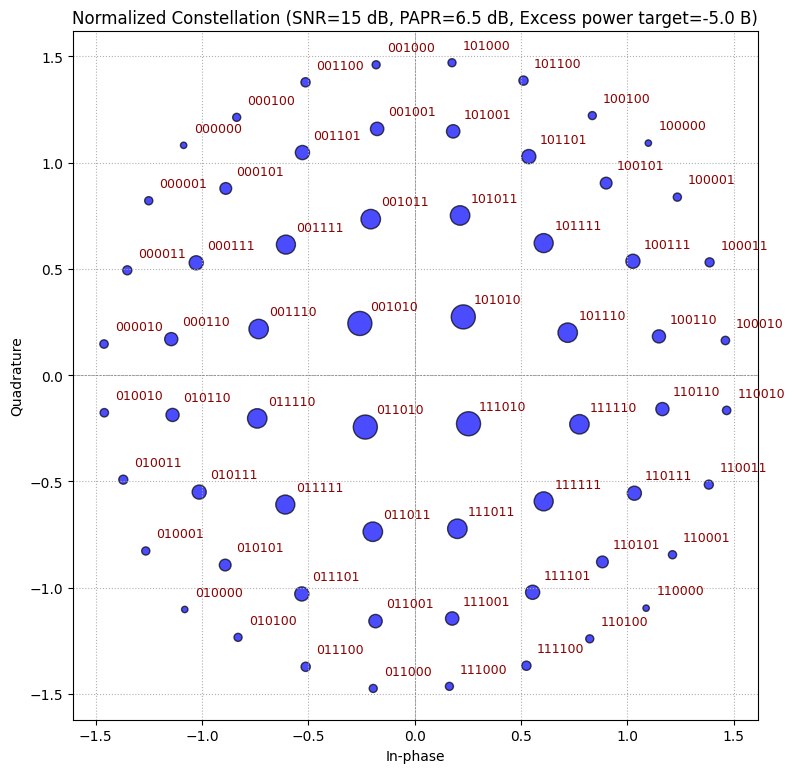

In [45]:
with tf.GradientTape(persistent=False) as tape:
#     tape.watch(model.trainable_variables)  # Ensure variables are watched if needed, but no gradients will be calculated
    _,_,_,shaping_probs = model(No)


# Define constellation points (complex numbers)
points = model.modulator.constellation_real.numpy()+ 1j*model.modulator.constellation_imag.numpy()

# Define probabilities for each point
probabilities = shaping_probs.numpy()
# probs_log = probabi
# plt.savefig('const.pdf')

# Normalize the constellation
normalized_points = normalize_constellation(points, probabilities)

title_plot = f"Normalized Constellation (SNR={snr_db} dB, PAPR={papr_threshold_db} dB, Excess power target={excess_power_target} B)"
# Plot the constellation
plot_constellation_wlabels(normalized_points, probabilities, title_plot)
file_name = f"snr_{snr_db}_PAPR_{papr_threshold_db}_target_{excess_power_target}"
print(probabilities)
print(file_name)

def entropy(pdf, base=2):
    pdf = np.asarray(pdf, dtype=np.float64)
    pdf = pdf[pdf > 0]  # remove zero entries to avoid log(0)
    pdf /= np.sum(pdf)  # normalize to ensure valid probability distribution

    h = -np.sum(pdf * np.log(pdf) / np.log(base))
    return h

print(entropy(probabilities))
